# T7-30: Load Data and Quality Check
**Project:** Customer Churn Analysis, Project Team 7 (WILDA26_09)  
**Owner:** Harjot Kaur, Data Engineer  
**Jira task:** T7-30 Load data and quality check (12 Oct 2026 to 18 Oct 2026)  
**Dataset:** Dataset_ATS_v2.csv

**Purpose.** This notebook loads the raw dataset and checks its quality before any cleaning is done. It checks the structure, data types, missing values, duplicates, category values, numeric ranges, logical consistency and the balance of the target variable. No changes are made to the data here. Cleaning and encoding follow in T7-31, and scaling and splitting in T7-32.

**How to run.** Open in Jupyter Notebook or Google Colab, the raw file is read from `Data_Preparation/raw_data/Dataset_ATS_v2.csv` (in Colab, upload it and change the path in the load cell), then select Run All. Charts are saved to the `figures` folder.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)
print('pandas', pd.__version__)

pandas 3.0.5


## 2. Load the raw data
The raw file is loaded as it was supplied. A separate copy (`df_raw`) is kept untouched so the original can always be checked later.

In [2]:
df_raw = pd.read_csv('../raw_data/Dataset_ATS_v2.csv')
df = df_raw.copy()
print('Rows:', df.shape[0], '| Columns:', df.shape[1])
df.head()

Rows: 7043 | Columns: 10


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1,Male,0,No,41,Yes,No,DSL,One year,25,No
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No


## 3. Structure and data types

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   gender           7043 non-null   str  
 1   SeniorCitizen    7043 non-null   int64
 2   Dependents       7043 non-null   str  
 3   tenure           7043 non-null   int64
 4   PhoneService     7043 non-null   str  
 5   MultipleLines    7043 non-null   str  
 6   InternetService  7043 non-null   str  
 7   Contract         7043 non-null   str  
 8   MonthlyCharges   7043 non-null   int64
 9   Churn            7043 non-null   str  
dtypes: int64(3), str(7)
memory usage: 550.4 KB


Seven columns are text and three are whole numbers: `SeniorCitizen` (already coded 0 and 1), `tenure` and `MonthlyCharges`. `Churn` is the target variable.

## 4. Missing values

In [4]:
missing = df.isna().sum().to_frame('missing_count')
missing['missing_pct'] = (missing['missing_count'] / len(df) * 100).round(2)
missing

,missing_count,missing_pct
gender,0,0.0
SeniorCitizen,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
Contract,0,0.0
MonthlyCharges,0,0.0
Churn,0,0.0


In [5]:
# Check for blank strings that pandas would not count as missing
blank = (df.select_dtypes(exclude='number').apply(lambda s: s.str.strip() == '')).sum()
print('Blank text values per column:'); print(blank)

Blank text values per column:
gender             0
Dependents         0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
Churn              0
dtype: int64


## 5. Duplicate rows

In [6]:
dup_count = df.duplicated().sum()
print('Exact duplicate rows:', dup_count, f'({dup_count/len(df)*100:.1f}% of rows)')
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

Exact duplicate rows: 302 (4.3% of rows)


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1539,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1907,Female,0,No,1,Yes,No,DSL,Month-to-month,20,No
3227,Female,0,No,1,Yes,No,DSL,Month-to-month,20,No
5085,Female,0,No,1,Yes,No,DSL,Month-to-month,20,No
6531,Female,0,No,1,Yes,No,DSL,Month-to-month,20,No


The file has no customer ID, so identical rows may be different customers who share the same values. The treatment (keep or remove) needs a team decision before cleaning in T7-31.

## 6. Category values

In [7]:
for col in df.select_dtypes(exclude='number').columns:
    print(f'{col}: {df[col].value_counts().to_dict()}')

gender: {'Male': 3555, 'Female': 3488}
Dependents: {'No': 4933, 'Yes': 2110}
PhoneService: {'Yes': 6361, 'No': 682}
MultipleLines: {'No': 4072, 'Yes': 2971}
InternetService: {'DSL': 3947, 'Fiber optic': 3096}
Contract: {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
Churn: {'No': 5174, 'Yes': 1869}


All categorical columns contain only the expected values. There are no spelling variations or unexpected categories.

## 7. Numeric ranges

In [8]:
df[['SeniorCitizen','tenure','MonthlyCharges']].describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.00
25%,0.00,9.00,36.00
50%,0.00,29.00,70.00
75%,0.00,55.00,90.00
max,1.00,72.00,119.00


In [9]:
zero_tenure = (df['tenure'] == 0).sum()
print('Customers with tenure = 0 months:', zero_tenure)
df[df['tenure'] == 0].head()

Customers with tenure = 0 months: 11


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
765,Female,0,Yes,0,Yes,No,DSL,Month-to-month,73,No
1413,Male,0,Yes,0,Yes,Yes,Fiber optic,Two year,62,No
1691,Female,0,Yes,0,No,No,DSL,Two year,56,No
3828,Male,0,Yes,0,Yes,No,DSL,Two year,25,No
4143,Male,0,Yes,0,Yes,Yes,Fiber optic,Month-to-month,20,No


## 8. Logical consistency check
A customer with no phone service should not have multiple phone lines.

In [10]:
pd.crosstab(df['PhoneService'], df['MultipleLines'], margins=True)

MultipleLines,No,Yes,All
PhoneService,,,
No,422,260,682
Yes,3650,2711,6361
All,4072,2971,7043


In [11]:
inconsistent = ((df['PhoneService'] == 'No') & (df['MultipleLines'] == 'Yes')).sum()
print('Records with MultipleLines = Yes but PhoneService = No:', inconsistent)

Records with MultipleLines = Yes but PhoneService = No: 260


## 9. Target variable balance

       count  percent
Churn                
No      5174     73.5
Yes     1869     26.5


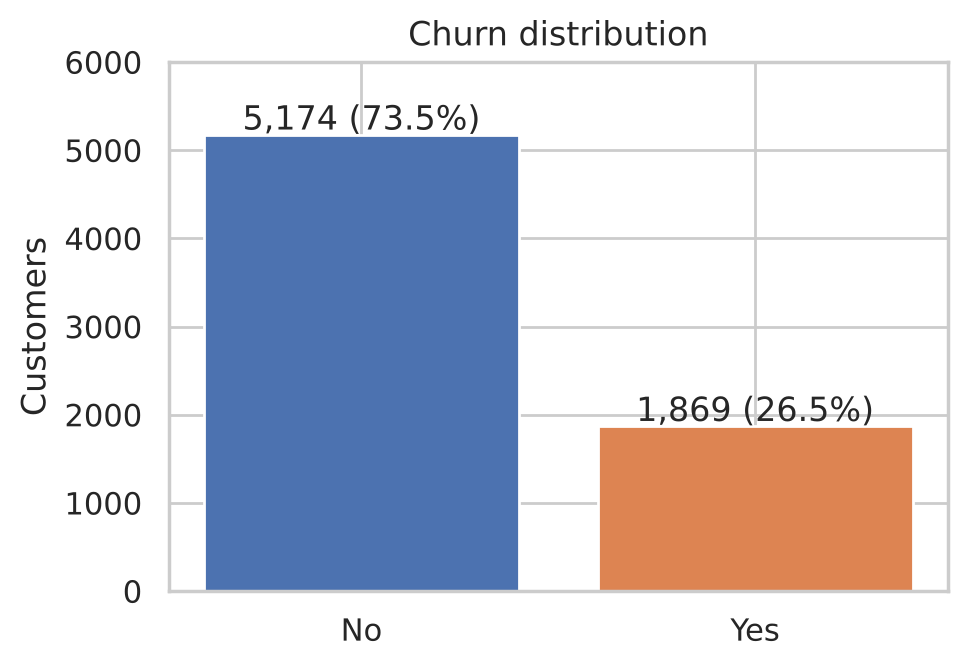

In [12]:
churn_counts = df['Churn'].value_counts()
churn_pct = (df['Churn'].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({'count': churn_counts, 'percent': churn_pct}))

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(churn_counts.index, churn_counts.values, color=['#4C72B0', '#DD8452'])
for b, p in zip(bars, churn_pct.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 60, f'{int(b.get_height()):,} ({p}%)', ha='center')
ax.set_title('Churn distribution'); ax.set_ylabel('Customers'); ax.set_ylim(0, 6000)
plt.tight_layout(); plt.savefig('figures/churn_distribution.png', dpi=150); plt.show()

Only 26.5% of customers churned. This imbalance will be handled with a stratified split in T7-32 and passed to the Predictive Modelling Analyst.

## 10. Distribution of numeric fields

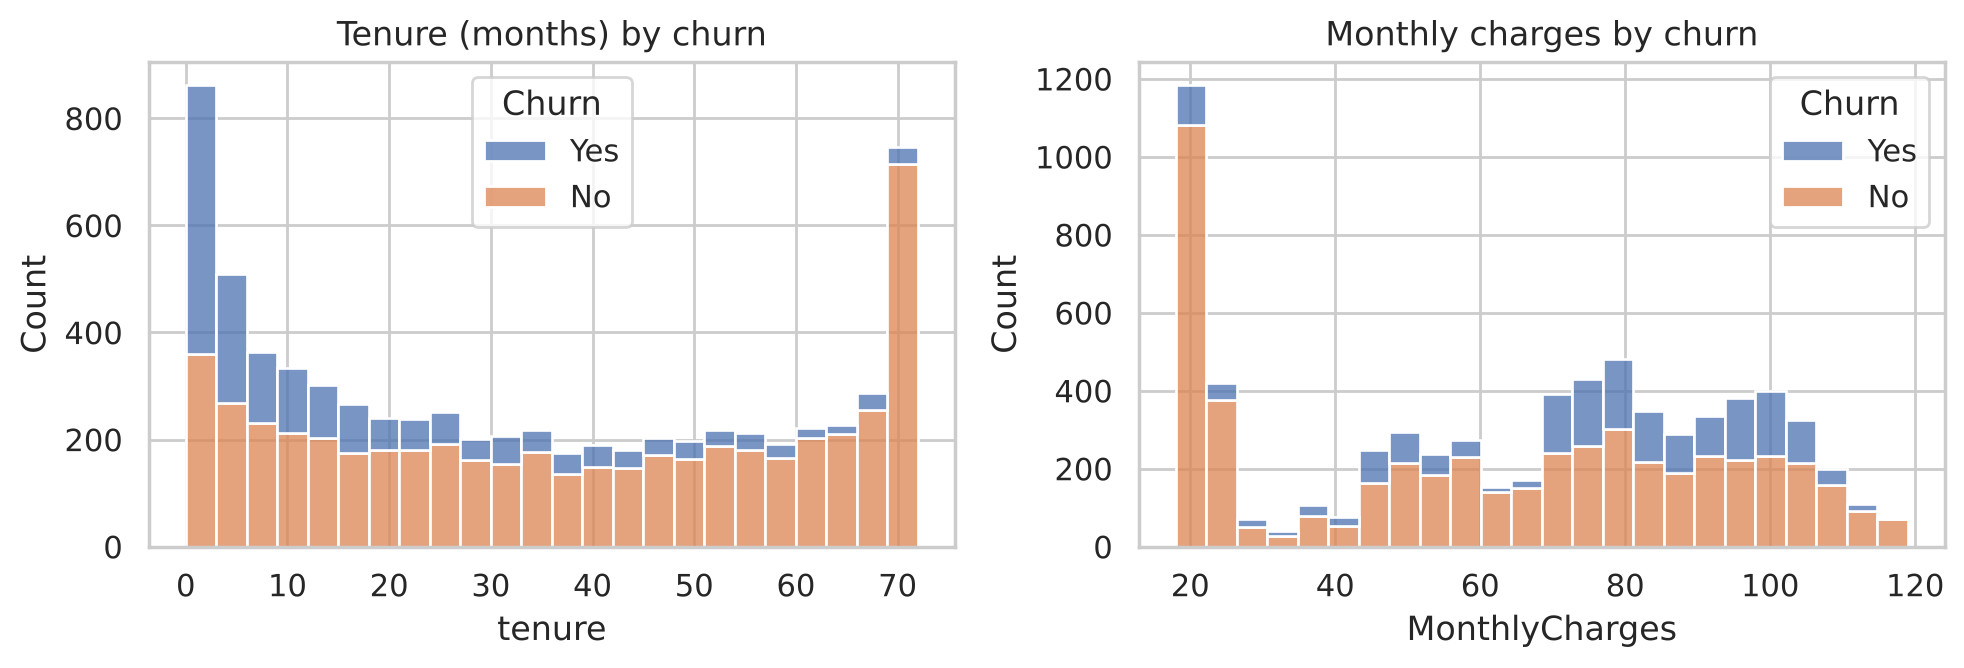

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(df, x='tenure', hue='Churn', bins=24, multiple='stack', ax=axes[0])
axes[0].set_title('Tenure (months) by churn')
sns.histplot(df, x='MonthlyCharges', hue='Churn', bins=24, multiple='stack', ax=axes[1])
axes[1].set_title('Monthly charges by churn')
plt.tight_layout(); plt.savefig('figures/numeric_distributions.png', dpi=150); plt.show()

The two numeric fields have very different ranges (0 to 72 and 18 to 119), so they will be scaled in T7-32.

## 11. Churn rate by customer group (initial view)

SeniorCitizen {0: 23.6, 1: 41.7}
Dependents {'No': 31.3, 'Yes': 15.5}
Contract {'Month-to-month': 27.3, 'One year': 25.8, 'Two year': 25.4}
InternetService {'DSL': 27.4, 'Fiber optic': 25.4}


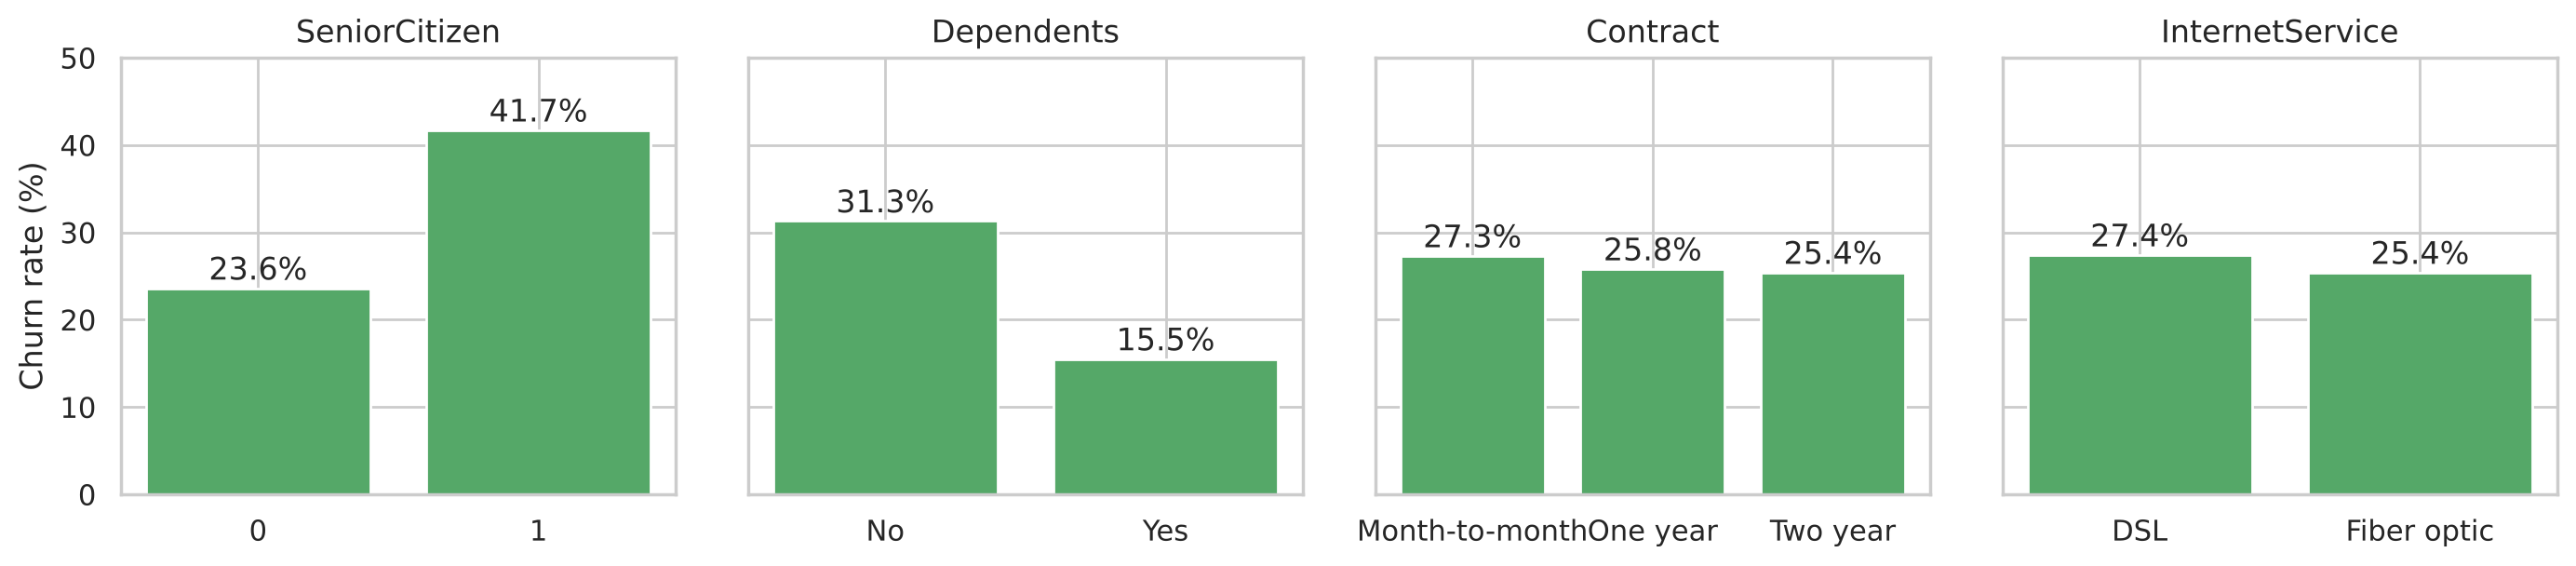

In [14]:
cols = ['SeniorCitizen', 'Dependents', 'Contract', 'InternetService']
rates = {c: (df.groupby(c)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)).round(1) for c in cols}
for c, r in rates.items():
    print(c, r.to_dict())

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, (c, r) in zip(axes, rates.items()):
    ax.bar(r.index.astype(str), r.values, color='#55A868')
    ax.set_title(c); ax.set_ylim(0, 50)
    for i, v in enumerate(r.values): ax.text(i, v + 1, f'{v}%', ha='center')
axes[0].set_ylabel('Churn rate (%)')
plt.tight_layout(); plt.savefig('figures/churn_by_group.png', dpi=150); plt.show()

These are descriptive figures only, shared to help the analysts. Senior citizens and customers without dependents show higher churn, while churn changes little by contract type.

## 12. Quality check summary

In [15]:
summary = pd.DataFrame([
    ['Missing values', 0, 'None found', 'No action needed'],
    ['Exact duplicate rows', int(dup_count), 'No customer ID to tell them apart', 'Team to decide keep or remove (Meeting 2)'],
    ['MultipleLines = Yes with PhoneService = No', int(inconsistent), 'Logically inconsistent', 'Proposed: recode MultipleLines to No and log it'],
    ['Tenure = 0 months', int(zero_tenure), 'New customers', 'Proposed: keep and review churn labels'],
    ['Churn imbalance (Yes)', f"{churn_pct['Yes']}%", 'Minority class', 'Stratified split (T7-32); flag to Shivani'],
    ['Different numeric scales', '2 columns', 'tenure 0-72, MonthlyCharges 18-119', 'Standard scaling (T7-32)'],
], columns=['Check', 'Result', 'Note', 'Proposed treatment'])
summary

,Check,Result,Note,Proposed treatment
0,Missing values,0,None found,No action needed
1,Exact duplicate rows,302,No customer ID to tell them apart,Team to decide keep or remove (Meeting 2)
2,MultipleLines = Yes with PhoneService = No,260,Logically inconsistent,Proposed: recode MultipleLines to No and log it
3,Tenure = 0 months,11,New customers,Proposed: keep and review churn labels
4,Churn imbalance (Yes),26.5%,Minority class,Stratified split (T7-32); flag to Shivani
5,Different numeric scales,2 columns,"tenure 0-72, MonthlyCharges 18-119",Standard scaling (T7-32)


## 13. Status and next steps
- **T7-30 (this notebook):** data loaded and quality checked. No changes made to the data.
- **Decisions needed at Meeting 2 (17 Oct 2026):** treatment of the 302 duplicate rows and the 260 inconsistent MultipleLines records.
- **T7-31:** clean and encode the data (Yes/No to 1/0, one-hot encode Contract and InternetService).
- **T7-32:** scale tenure and MonthlyCharges and create the stratified train, validation and test split.
- **T7-33:** hand over the clean data to Dilina and Shivani.
- **T7-34:** data quality note, data dictionary and cleaning log.